In [1]:
import pandas as pd
df=pd.read_csv("02_multiple_linear_house_price.csv")
df

,Area_sqft,Bedrooms,House_Age_years,Distance_to_CityCenter_km,Price_Lakhs
0,2670.0,1,6,6.89,229.10
1,2879.0,2,8,4.78,250.73
2,953.0,3,18,4.85,73.10
3,2824.0,2,15,9.02,212.84
4,1781.0,2,7,6.73,170.09
...,...,...,...,...,...
245,1404.0,1,5,8.94,115.12
246,2527.0,2,23,11.77,196.83
247,611.0,5,18,17.07,45.22
248,1400.0,2,15,4.50,112.05


In [ ]:
x=df.drop(columns=['Price_Lakhs'])
y=df['Price_Lakhs']

0      229.10
1      250.73
2       73.10
3      212.84
4      170.09
        ...  
245    115.12
246    196.83
247     45.22
248    112.05
249    154.05
Name: Price_Lakhs, Length: 250, dtype: float64

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x,y,train_size=0.8)
X_train.head()

,Area_sqft,Bedrooms,House_Age_years,Distance_to_CityCenter_km
240,2688.0,2,7,10.52
228,1983.0,1,16,10.72
147,1035.0,5,1,20.71
132,1374.0,5,6,12.58
87,2968.0,5,4,18.16


In [14]:
Y_test.head()

2       73.10
173    131.36
198     33.64
19     104.66
39      58.94
Name: Price_Lakhs, dtype: float64

In [17]:
from sklearn import linear_model
model = linear_model.LinearRegression()
model.fit(X_train,Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
from sklearn.metrics import r2_score

y_pred = model.predict(X_test)
score = r2_score(Y_test,y_pred)
print(f"Accuracy (R² Score): {score * 100:.2f}%")

Accuracy (R² Score): 96.26%


In [24]:
Area_sqft = float(input("Enter the Sqft: "))
Bedrooms = int(input("Enter No of Bedrooms: "))
House_Age_years = int(input("Enter the Age of the House: "))
Distance_to_CityCenter_km = float(input("Enter the Distance from city: "))

input_data = pd.DataFrame({
    'Area_sqft': [Area_sqft],
    'Bedrooms': [Bedrooms],
    'House_Age_years': [House_Age_years],
    'Distance_to_CityCenter_km': [Distance_to_CityCenter_km]
})

predicted_value = model.predict(input_data)
print(f"\nPredicted House Price: ₹{predicted_value[0]:.2f} Lakhs")


Predicted House Price: ₹229.33 Lakhs


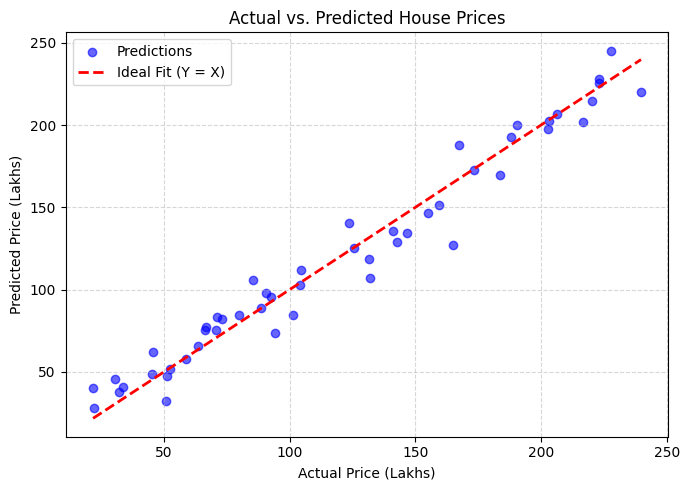

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

# Scatter plot comparing actual values against model predictions
plt.scatter(Y_test, y_pred, color='blue', alpha=0.6, label='Predictions')

# Diagonal line showing perfect predictions
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2, label='Ideal Fit (Y = X)')

plt.xlabel('Actual Price (Lakhs)')
plt.ylabel('Predicted Price (Lakhs)')
plt.title('Actual vs. Predicted House Prices')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()